In [ ]:
from agentic_synth_data.workflow import DataGen

# Datasets for testing
#data_path = "../data/cat_texas.csv" # from PUDF_base1_1q2019 (mostly categorical)
#data_path = "../data/num_iris.csv" # (mostly numerical)
data_path = "../data/mix_titanic.csv" # (mix of categorical and numerical)
#data_path = "../data/short_PUDF_base1_1q2019_tab.csv"

# Input initial dataset
gen = DataGen(data_path)
gen.load_dataframe()
gen.apply_preferences()

In [ ]:
# Conduct dtype, semantic type, and missing value handling
gen.preprocess_dtypes()

In [ ]:
gen.generator_selection()

In [ ]:
gen.preprocess_missing_vals()

In [ ]:
# Save data and prepare for generator use
gen.save_prepared_data()
gen.create_metadata()

In [ ]:
# Suggest a generator and synthesize data
gen.run_synthesis() 

In [ ]:
# Evaluate the results
gen.evaluate()

---

Running everything together.

=========================[STEP: Select preferences]=========================
Would you like to generate the same amount of samples as the dataset or a fixed number of samples?
Please select one of the following:
1. fixed value
2. same as original

Are you interested in differential privacy?


Is there a specific data generator that you want to use on your data? Select 'auto' if you would
like a suggestion.
Please select one of the following:
1. auto
2. CTGAN
3. PATEGAN
4. BayesianNet
5. PrivBayes
	=> You will receive a recommendation based on the dataset's characteristics.

How would you like missing values to be handled? Select 'auto' if you would like a suggestion.
Please select one of the following:
1. auto
2. impute
3. threshold
4. remove

-------------------------Your preferences have been recorded-------------------------

Sample size mode: same_as_original
Privacy mode: differential_privacy
Generator: auto
Missing value handling: remove



=========================[STEP: Normali

Categories {nan} in column 'embarked' are in real data but not in synthetic data. They will not be considered in the score computation.
Dropped 1 columns due to high missingness (threshold is 0.9).
Removed 1 entries due to missing values.



=> PATEGAN: 200 synthetic samples successfully generated.



=========================[STEP: Evaluate synthetic data]=========================

Jenson-Shannon Distances:
age 0.3796
fare 0.8841
sibsp 0.4488
parch 0.569
sex 0.0951
embarked 0.4052
class 0.1986
alone 0.056
jsd_AVERAGE 0.3795

Normalized correlation difference: 1.0613

Discriminator AUC: 0.9988

Distribution plot for: age.png


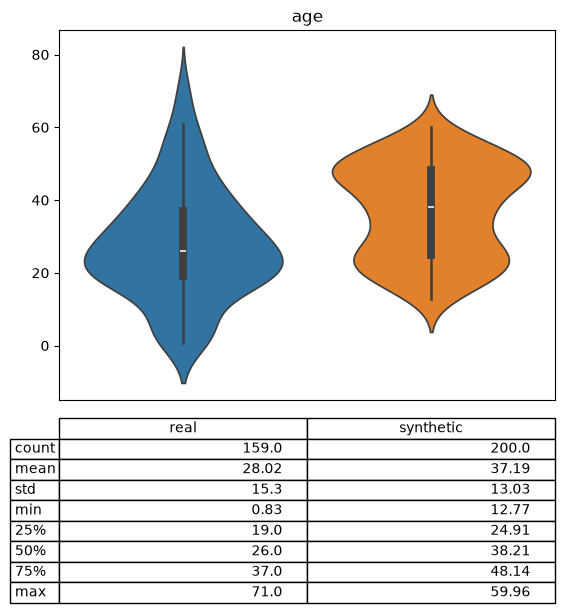


=> Distribution plots for all features saved to: ../output/plots/version_1

Agent is evaluating the results...

Evaluation:
- Status: not_satisfactory
- Problem columns: ['fare', 'parch', 'sibsp', 'age', 'embarked']
- Recommendation:
Generator selection should be revisited. Consider switching from PATEGAN to BayesianNet or
PrivBayes, which may handle this mixed categorical/numerical data better on small datasets with 200
rows.
- Rationale:
The average JSD of 0.38 is well above the 0.25 threshold, indicating poor marginal distribution
fidelity. Five columns have JSD > 0.35, with fare being particularly problematic at 0.88. The
normalized correlation difference of 1.06 shows weak preservation of feature dependencies, and the
discriminator AUC of 0.999 indicates synthetic data is easily distinguishable from real data. These
primary metrics collectively provide substantial evidence of poor fidelity across multiple
dimensions. PATEGAN may not be well-suited for this small dataset with mixe

Categories {nan} in column 'embarked' are in real data but not in synthetic data. They will not be considered in the score computation.
Dropped 1 columns due to high missingness (threshold is 0.9).
Removed 1 entries due to missing values.



=> CTGAN: 200 synthetic samples successfully generated.



=========================[STEP: Evaluate synthetic data]=========================

Jenson-Shannon Distances:
age 0.1076
fare 0.1549
sibsp 0.0932
parch 0.1625
sex 0.1022
embarked 0.1059
class 0.0674
alone 0.1278
jsd_AVERAGE 0.1152

Normalized correlation difference: 0.4975

Discriminator AUC: 0.8463

Distribution plot for: age.png


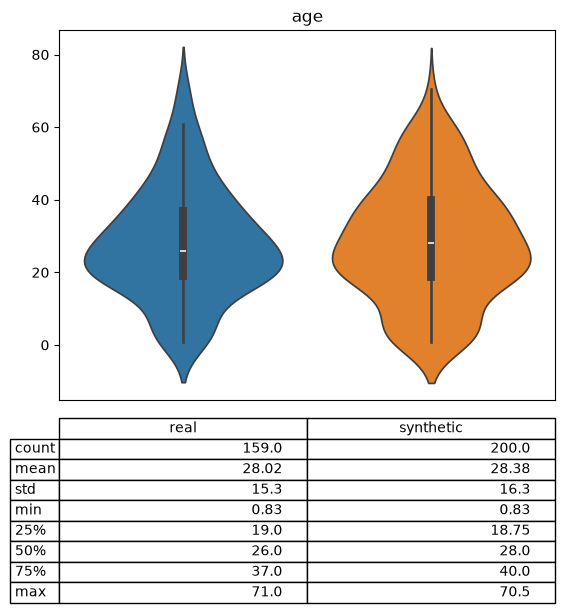


=> Distribution plots for all features saved to: ../output/plots/version_2

Agent is evaluating the results...

Evaluation:
- Status: needs_review
- Recommendation:
Consider generator re-selection. CTGAN shows improved fidelity over PATEGAN (average JSD 0.115 vs
0.38), but still falls in the review range. No columns exceed JSD 0.20, indicating acceptable
marginal distributions. The correlation difference of 0.50 and discriminator AUC of 0.85 are
moderate. Consider trying BayesianNet or PrivBayes as alternatives to potentially improve further.
- Rationale:
The average JSD of 0.115 is just above the 0.10 threshold that strongly supports satisfactory,
placing it in the review range. However, no individual columns exceed JSD 0.20, indicating all
marginal distributions are reasonably preserved. The correlation difference of 0.50 shows moderate
relationship preservation. The discriminator AUC of 0.85 is elevated but is a supporting indicator
only. CTGAN represents a significant improvement 

,age,fare,sibsp,parch,sex,embarked,class,alone
0,20.0,16.1000,0,0,male,S,Second,False
1,55.5,79.2000,0,0,male,S,Third,True
2,38.0,39.6875,0,0,male,S,Second,True
3,19.0,247.5208,0,1,male,S,First,False
4,27.0,26.0000,5,0,female,S,Third,True
...,...,...,...,...,...,...,...,...
195,4.0,7.0500,4,0,male,S,Third,False
196,21.0,21.0750,0,5,female,S,First,True
197,29.0,8.0500,0,0,male,S,Third,True
198,14.0,12.5250,0,0,male,S,Third,True


In [1]:
from agentic_synth_data.workflow import DataGen

# Dataset path
data_path = "../data/mix_titanic.csv" # (mix of categorical and numerical)
#data_path = "../data/cat_texas.csv" # from PUDF_base1_1q2019 (mostly categorical)
#data_path = "../data/num_iris.csv" # (mostly numerical)
#data_path = "../data/mix_titanic.csv" # (mix of categorical and numerical)
#data_path = "../data/short_PUDF_base1_1q2019_tab.csv"

# Input initial dataset
gen = DataGen(data_path)

# Run workflow
gen.run()